# Design 4: a second opinion from Kaggle lookalikes (prototype)

Static matplotlib prototype. For each of my draws, find the 50 Kaggle patients whose TSH and T3 are
closest to mine, and show what they were diagnosed with. Above each bar is what my own doctor called it.
Where the two disagree, the same numbers are being read differently for a known Graves patient on
medication than for a stranger with the same blood test.

- Kaggle data: `data/thyroidDF.csv`, patients with both TSH and T3. Groups follow Joel's mapping
  (A–D hyper, E–H hypo, `-` normal); other diagnosis codes are left out. Ages over 100 are typos and dropped.
- My data: `data/personal_thyroid.csv`. T3 is in nmol/L, the Kaggle unit.
- The first two draws (Jan 29 and Feb 1, 2024) each have only one of the two labs, so they're merged
  into one diagnosis point, same as design 3. Jun 1, 2025 has no T3 and is skipped.
- "Closest" is distance on log TSH and T3, each scaled by its standard deviation across Kaggle patients.
- Bars are evenly spaced, one per draw. The gaps between draws aren't to scale.
- Caveat: a Kaggle label is one diagnosis per patient, not a per-draw status like mine.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

DATA = Path("..") / "data"
GROUP_BY_CODE = {**{c: "hyper" for c in "ABCD"}, **{c: "hypo" for c in "EFGH"}, "-": "normal"}
K = 50

kaggle = pd.read_csv(DATA / "thyroidDF.csv", usecols=["age", "TSH", "T3", "target"])
kaggle["group"] = kaggle["target"].astype(str).str[0].map(GROUP_BY_CODE)
kaggle = kaggle.dropna(subset=["group", "TSH", "T3"])
kaggle = kaggle[kaggle["age"] <= 100].copy()
kaggle["TSH"] = kaggle["TSH"].clip(lower=0.005)

personal = pd.read_csv(DATA / "personal_thyroid.csv", usecols=["date", "TSH", "T3", "lab_status", "methimazole_mg"])
personal["date"] = pd.to_datetime(personal["date"], format="mixed")
personal = personal.sort_values("date").reset_index(drop=True)
first_two = personal.iloc[:2]
diagnosis = first_two.iloc[1].copy()
diagnosis["TSH"] = first_two["TSH"].dropna().iloc[0]
diagnosis["T3"] = first_two["T3"].dropna().iloc[0]
draws = pd.concat([diagnosis.to_frame().T, personal.iloc[2:]], ignore_index=True)
draws = draws.dropna(subset=["TSH", "T3"]).reset_index(drop=True)
draws[["TSH", "T3", "methimazole_mg"]] = draws[["TSH", "T3", "methimazole_mg"]].astype(float)

GROUPS = ["hyper", "normal", "hypo"]
GROUP_COLORS = {"hyper": "#e34948", "normal": "#1baf7a", "hypo": "#2a78d6"}
STATUS_COLORS = {"hyperthyroid": "#e34948", "subclinical_hyper": "#eda100", "euthyroid": "#1baf7a",
                 "subclinical_hypo": "#6250d6", "hypothyroid": "#2a78d6"}
STATUS_SHORT = {"hyperthyroid": "hyper", "subclinical_hyper": "subclin.\nhyper", "euthyroid": "normal",
                "subclinical_hypo": "subclin.\nhypo", "hypothyroid": "hypo"}
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#a3a29c"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})

## Find each draw's lookalikes

In [2]:
features = np.column_stack([np.log10(kaggle["TSH"]), kaggle["T3"]])
scale = features.std(axis=0)


def lookalike_shares(tsh, t3, k=K):
    q = np.array([np.log10(max(tsh, 0.005)), t3])
    dist = (((features - q) / scale) ** 2).sum(axis=1)
    nearest = kaggle["group"].to_numpy()[np.argsort(dist)[:k]]
    return {g: (nearest == g).mean() for g in GROUPS}


shares = pd.DataFrame([lookalike_shares(r["TSH"], r["T3"]) for _, r in draws.iterrows()])
draws = pd.concat([draws, shares], axis=1)
draws[["date", "TSH", "T3", "lab_status", "methimazole_mg"] + GROUPS]

,date,TSH,T3,lab_status,methimazole_mg,hyper,normal,hypo
0,2024-02-01 00:00:00,0.01,6.45,hyperthyroid,0.0,0.78,0.22,0.00
1,2024-03-21 00:00:00,0.01,2.92,subclinical_hyper,10.0,0.36,0.64,0.00
2,2024-05-20 00:00:00,0.45,1.23,hypothyroid,10.0,0.00,1.00,0.00
3,2024-06-26 00:00:00,0.01,4.45,hyperthyroid,0.0,0.74,0.26,0.00
4,2024-08-07 00:00:00,0.01,2.00,subclinical_hyper,7.5,0.12,0.88,0.00
5,2024-10-11 00:00:00,0.01,2.46,subclinical_hyper,5.0,0.16,0.84,0.00
6,2024-12-09 00:00:00,0.26,1.54,subclinical_hyper,5.0,0.02,0.98,0.00
7,2025-03-21 00:00:00,2.31,1.54,euthyroid,5.0,0.00,1.00,0.00
8,2025-06-05 00:00:00,1.50,1.84,euthyroid,5.0,0.00,1.00,0.00
9,2025-10-21 00:00:00,4.13,1.69,euthyroid,5.0,0.00,1.00,0.00


## The plot

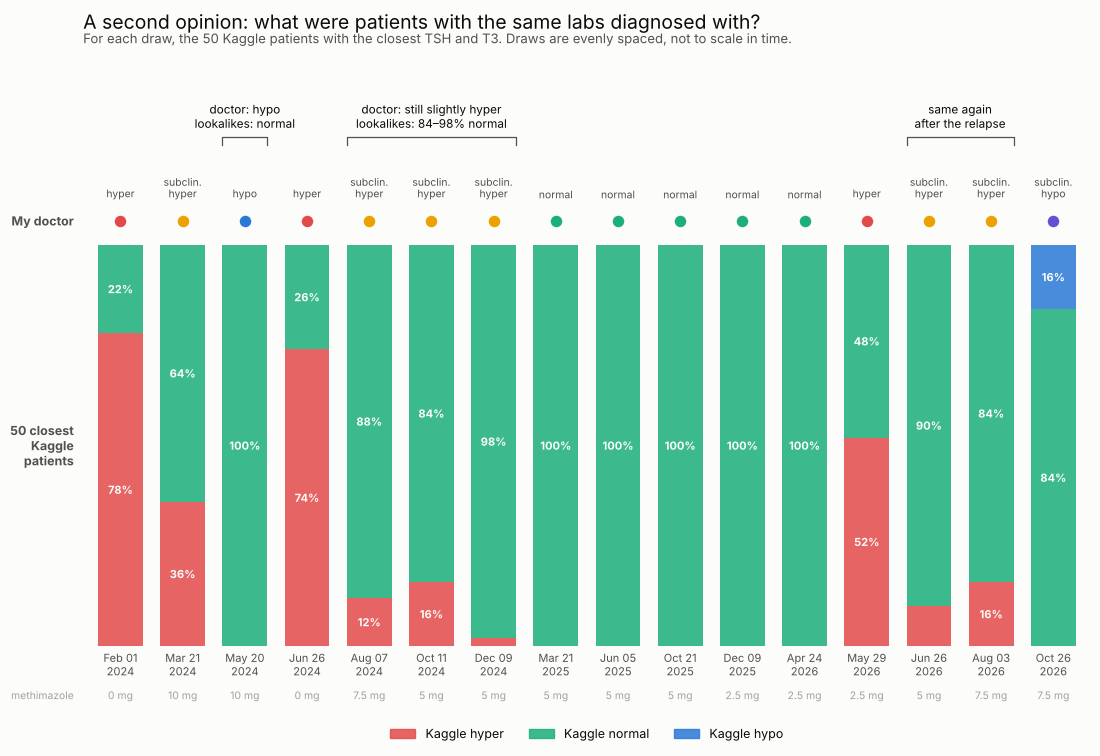

In [3]:
n = len(draws)
x = np.arange(n)
fig, ax = plt.subplots(figsize=(13, 7.4))

bottom = np.zeros(n)
for g in GROUPS:
    ax.bar(x, draws[g], bottom=bottom, width=0.72, color=GROUP_COLORS[g], alpha=0.85, lw=0,
           label=f"Kaggle {g}", zorder=2)
    for xi, b, v in zip(x, bottom, draws[g]):
        if v >= 0.12:
            ax.text(xi, b + v / 2, f"{v:.0%}", ha="center", va="center", fontsize=8, color=SURFACE,
                    fontweight="bold", zorder=3)
    bottom += draws[g].to_numpy()

# Doctor's call above each bar.
for xi, s in zip(x, draws["lab_status"]):
    ax.scatter(xi, 1.06, s=90, color=STATUS_COLORS[s], edgecolor=SURFACE, lw=1.2, zorder=3, clip_on=False)
    ax.text(xi, 1.11, STATUS_SHORT[s], ha="center", va="bottom", fontsize=7.5, color=INK2, linespacing=1.0)
ax.text(-0.75, 1.06, "My doctor", ha="right", va="center", fontsize=9, fontweight="bold", color=INK2)
ax.text(-0.75, 0.5, f"{K} closest\nKaggle\npatients", ha="right", va="center", fontsize=9,
        fontweight="bold", color=INK2)

# Brackets over the stretches where the doctor and lookalikes disagree most.
def bracket(i0, i1, text):
    y = 1.27
    ax.plot([i0 - 0.36, i0 - 0.36, i1 + 0.36, i1 + 0.36], [y - 0.02, y, y, y - 0.02], color=INK2, lw=0.9,
            clip_on=False)
    ax.text((i0 + i1) / 2, y + 0.015, text, ha="center", va="bottom", fontsize=8.5, color=INK, clip_on=False)


dates = [f"{d:%Y-%m-%d}" for d in draws["date"]]
bracket(dates.index("2024-08-07"), dates.index("2024-12-09"),
        "doctor: still slightly hyper\nlookalikes: 84–98% normal")
bracket(dates.index("2026-06-26"), dates.index("2026-08-03"),
        "same again\nafter the relapse")
bracket(dates.index("2024-05-20"), dates.index("2024-05-20"), "doctor: hypo\nlookalikes: normal")

ax.set_xticks(x)
ax.set_xticklabels([f"{d:%b %d\n%Y}" for d in draws["date"]], fontsize=8)
ax.set_xlim(-0.6, n - 0.4)
ax.set_ylim(0, 1.42)
ax.set_yticks([])
ax.tick_params(axis="x", length=0)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)

# Dose under each date.
for xi, mg in zip(x, draws["methimazole_mg"]):
    ax.text(xi, -0.075, f"{mg:g} mg", ha="center", va="top", fontsize=7.5, color=MUTED, transform=ax.get_xaxis_transform())
ax.text(-0.75, -0.075, "methimazole", ha="right", va="top", fontsize=7.5, color=MUTED,
        transform=ax.get_xaxis_transform())

ax.legend(handles=[Patch(color=GROUP_COLORS[g], alpha=0.85, label=f"Kaggle {g}") for g in GROUPS],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=9)
fig.suptitle("A second opinion: what were patients with the same labs diagnosed with?",
             x=0.125, y=0.97, ha="left", fontsize=14)
fig.text(0.125, 0.925, f"For each draw, the {K} Kaggle patients with the closest TSH and T3. "
         "Draws are evenly spaced, not to scale in time.", fontsize=9.5, color=INK2)
fig.savefig("lookalikes.png", dpi=110, bbox_inches="tight")
plt.show()